# Naive Bayes จำแนกดาวรีวิวร้านอาหารไทย (Wongnai)

ทายจำนวนดาว (1-5) จากข้อความรีวิว ด้วย **Naive Bayes** ตามสไลด์ *08 Bayesian Learning* (สไลด์ 29)

ขั้นตอน: อ่านข้อมูล → แบ่งเรียน/ทดสอบ → ตัดคำไทย → Vocabulary → **Learn** → **Classify** → Performance test → Heat map → Word cloud

รายละเอียดโจทย์อยู่ใน `Ice.md`

> รันจากโฟลเดอร์โปรเจกต์นี้ (ต้องมี `fonts/Sarabun-Regular.ttf`) ส่วน `data/` ถ้าไม่มีจะโหลดจาก GitHub ให้เองในข้อ 1
> ไลบรารี: numpy, matplotlib, pythainlp, wordcloud

In [10]:
import csv
import os
import random
import time
import urllib.request
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pythainlp.tokenize import word_tokenize
from pythainlp.corpus.common import thai_stopwords
from wordcloud import WordCloud

FONT = 'fonts/Sarabun-Regular.ttf'          # ฟอนต์ไทยสำหรับวาดภาพ (ไม่เกี่ยวกับการคำนวณ)
font_manager.fontManager.addfont(FONT)
plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT).get_name()

random.seed(0)                              # ผลซ้ำเดิมทุกครั้ง

## 1. อ่านข้อมูล
ใช้ `w_review_train.csv` จาก [wongnai-corpus](https://github.com/wongnai/wongnai-corpus) (40,000 รีวิว มีดาว 1-5)
ไฟล์คั่นด้วย `;` ไม่มีบรรทัดหัวตาราง และบางรีวิวขึ้นบรรทัดใหม่ จึงอ่านด้วย `csv` module

In [11]:
CSV = 'data/w_review_train.csv'
URL = 'https://raw.githubusercontent.com/wongnai/wongnai-corpus/master/review/review_dataset.zip'

if not os.path.exists(CSV):                 # ยังไม่มีไฟล์ -> โหลดจาก GitHub
  os.makedirs('data', exist_ok=True)
  urllib.request.urlretrieve(URL, 'data/review_dataset.zip')
  with zipfile.ZipFile('data/review_dataset.zip') as z:
    z.extract('w_review_train.csv', 'data')
  os.remove('data/review_dataset.zip')

csv.field_size_limit(10**9)
reviews = []                                # ข้อความรีวิว
stars = []                                  # ดาว 1-5
with open(CSV, encoding='utf-8', newline='') as f:
  for text, star in csv.reader(f, delimiter=';'):
    reviews.append(text)
    stars.append(int(star))
stars = np.array(stars)

print('จำนวนรีวิว =', len(reviews))
for s in range(1, 6):
  print(s, 'ดาว :', np.sum(stars == s), 'รีวิว')

จำนวนรีวิว = 40000
1 ดาว : 415 รีวิว
2 ดาว : 1845 รีวิว
3 ดาว : 12171 รีวิว
4 ดาว : 18770 รีวิว
5 ดาว : 6799 รีวิว


## 2. แบ่งชุดเรียน / ชุดทดสอบ
สุ่มสลับลำดับ แล้วแบ่ง 80 / 20 (`test_file.csv` ของ Kaggle ไม่มีเฉลย จึงไม่ใช้)

In [12]:
N = len(reviews)
idx = list(range(N))
random.shuffle(idx)
n_train = int(N * 0.8)
train_idx = idx[:n_train]                   # 32,000 รีวิว ไว้เรียน
test_idx = idx[n_train:]                    # 8,000 รีวิว ไว้ทดสอบ
print('ชุดเรียน =', len(train_idx), '| ชุดทดสอบ =', len(test_idx))

ชุดเรียน = 32000 | ชุดทดสอบ = 8000


## 3. ตัดคำไทย
ตัดคำด้วย PyThaiNLP (`newmm`) แล้วตัด stop words ช่องว่าง ตัวเลข และสัญลักษณ์ออก
(ไม่ทำ stemming เพราะภาษาไทยไม่มีการผันคำ)

In [13]:
stop = set(thai_stopwords())                # stop words ภาษาไทย 1,030 คำ

def clean(text):
  out = []
  for w in word_tokenize(text, engine='newmm'):
    w = w.strip().lower()
    if w and w not in stop and any(c.isalpha() for c in w):
      out.append(w)
  return out

# ตัวอย่างก่อน / หลังตัดคำ
print('ก่อน :', reviews[1][:90].replace('\n', ' '))
print('หลัง :', clean(reviews[1])[:15])

t = time.time()
docs = [clean(r) for r in reviews]          # รีวิวทุกอันเป็นรายการคำ
print('ตัดคำ 40,000 รีวิวใช้เวลา', round(time.time() - t), 'วินาที')

ก่อน : อาหารที่นี่เป็นอาหารจีนแคะที่หากินยากในบ้านเรา ตัวร้านตั้งอยู่ที่ถนนพุทธมณฑลสาย 3 ไปตาม ถ.
หลัง : ['อาหาร', 'ที่นี่', 'อาหารจีน', 'แคะ', 'หากิน', 'บ้าน', 'ตัว', 'ร้าน', 'ตั้งอยู่', 'ถนน', 'พุทธมณฑล', 'สาย', 'ถ.', 'ปิ่น', 'เกล้า']
ตัดคำ 40,000 รีวิวใช้เวลา 44 วินาที


## 4. Vocabulary
รวบรวมคำที่ไม่ซ้ำจาก **ชุดเรียนเท่านั้น** (คำที่เจอแต่ในชุดทดสอบถือเป็น OOV)

In [14]:
vocab = {}                                  # คำ -> เลขคอลัมน์
for i in train_idx:
  for w in docs[i]:
    if w not in vocab:
      vocab[w] = len(vocab)
V = len(vocab)
words = np.array(list(vocab.keys()))        # words[เลขคอลัมน์] = คำ
print('จำนวนคำใน Vocabulary =', V)

จำนวนคำใน Vocabulary = 39897


## 5. Learn (สไลด์ 29)
- `P(ดาว) = |docs ของดาวนั้น| / |ทั้งหมด|`
- `P(คำ | ดาว) = (n_k + 1) / (n + |Vocabulary|)` โดย `n_k` = จำนวนครั้งที่คำอยู่ในรีวิวของดาวนั้น, `n` = จำนวนคำทั้งหมดของดาวนั้น (+1 คือ Laplace กันค่า 0)

In [15]:
TF = np.zeros((5, V))                       # TF[ดาว-1, คำ] = จำนวนครั้งที่เจอ  (ตาราง V x 5)
n_docs = np.zeros(5)                        # จำนวนรีวิวของแต่ละดาว
for i in train_idx:
  s = stars[i] - 1
  n_docs[s] += 1
  for w in docs[i]:
    TF[s, vocab[w]] += 1

prior = n_docs / n_docs.sum()               # P(ดาว)
n = TF.sum(axis=1, keepdims=True)           # จำนวนคำทั้งหมดของแต่ละดาว
P = (TF + 1) / (n + V)                      # P(คำ | ดาว) แบบ Laplace
log_prior = np.log(prior)
log_P = np.log(P)

for s in range(5):
  print(s + 1, 'ดาว : P(ดาว) =', round(prior[s], 3), '| จำนวนคำ =', int(n[s, 0]))
print('ตาราง P(คำ | ดาว) ขนาด', P.shape[1], 'คำ x', P.shape[0], 'ดาว')

1 ดาว : P(ดาว) = 0.01 | จำนวนคำ = 22427
2 ดาว : P(ดาว) = 0.046 | จำนวนคำ = 111583
3 ดาว : P(ดาว) = 0.303 | จำนวนคำ = 662070
4 ดาว : P(ดาว) = 0.471 | จำนวนคำ = 1061763
5 ดาว : P(ดาว) = 0.17 | จำนวนคำ = 390438
ตาราง P(คำ | ดาว) ขนาด 39897 คำ x 5 ดาว


## 6. Classify
ทายดาวที่ `P(ดาว) × ∏ P(คำ | ดาว)` สูงสุด
- ข้ามคำที่ไม่อยู่ใน Vocabulary (OOV) เหมือน "John" ในตัวอย่างลายมือ
- ใช้ผลรวมของ `log` แทนผลคูณ กันค่าเล็กจนเป็น 0

In [16]:
def classify(doc_words):
  ids = [vocab[w] for w in doc_words if w in vocab]     # ข้ามคำ OOV
  score = log_prior + log_P[:, ids].sum(axis=1)         # คะแนนของแต่ละดาว (5 ค่า)
  return np.argmax(score) + 1

print('ตัวอย่าง: ดาวจริง =', stars[test_idx[0]], '| ทาย =', classify(docs[test_idx[0]]))

ตัวอย่าง: ดาวจริง = 4 | ทาย = 3


## 7. Performance test
ทายชุดทดสอบ 8,000 รีวิว แล้ววัด **Accuracy = ทายถูก ÷ ทั้งหมด** เทียบกับการเดาดาวที่พบมากที่สุดตลอด (baseline)

Accuracy (Naive Bayes)       = 51.2 %
Accuracy (เดา 4 ดาวตลอด)   = 46.3 %


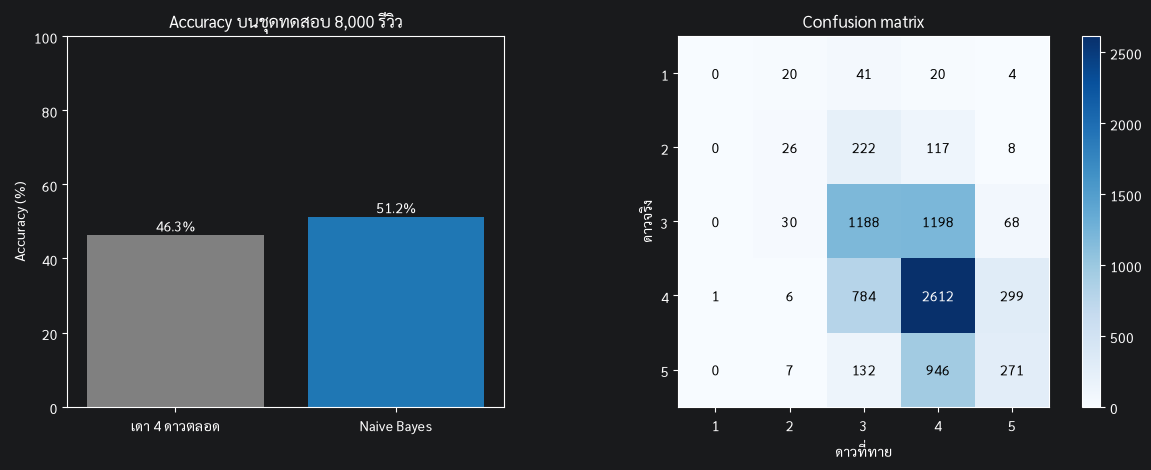

In [17]:
y_true = stars[test_idx]
y_pred = np.array([classify(docs[i]) for i in test_idx])

acc = np.mean(y_pred == y_true)
majority = np.argmax(n_docs) + 1            # ดาวที่พบมากที่สุดในชุดเรียน
baseline = np.mean(y_true == majority)

cm = np.zeros((5, 5), dtype=int)            # confusion matrix (แถว = ดาวจริง, คอลัมน์ = ดาวที่ทาย)
for t, p in zip(y_true, y_pred):
  cm[t - 1, p - 1] += 1

print('Accuracy (Naive Bayes)       =', round(acc * 100, 1), '%')
print('Accuracy (เดา', majority, 'ดาวตลอด)   =', round(baseline * 100, 1), '%')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1, 1.5]})
bars = ax[0].bar(['เดา %d ดาวตลอด' % majority, 'Naive Bayes'], [baseline * 100, acc * 100],
                 color=['gray', 'tab:blue'])
for b in bars:
  ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1, '%.1f%%' % b.get_height(), ha='center')
ax[0].set_ylim(0, 100)
ax[0].set_ylabel('Accuracy (%)')
ax[0].set_title('Accuracy บนชุดทดสอบ 8,000 รีวิว')

im = ax[1].imshow(cm, cmap='Blues')
for r in range(5):
  for c in range(5):
    ax[1].text(c, r, cm[r, c], ha='center', va='center',
               color='white' if cm[r, c] > cm.max() * 0.5 else 'black')
ax[1].set_xticks(range(5))
ax[1].set_xticklabels(range(1, 6))
ax[1].set_yticks(range(5))
ax[1].set_yticklabels(range(1, 6))
ax[1].set_xlabel('ดาวที่ทาย')
ax[1].set_ylabel('ดาวจริง')
ax[1].set_title('Confusion matrix')
fig.colorbar(im, ax=ax[1])
plt.tight_layout()
plt.show()

## 8. เลือกคำเด่นของแต่ละดาว
คำที่พบบ่อยในทุกดาว (เช่น ร้าน, อร่อย) ไม่ช่วยแยกดาว จึงวัดว่าคำนั้น **โดดเด่นในดาวนี้เมื่อเทียบกับดาวอื่น** แค่ไหน:
`log P(คำ | ดาวนี้) − log P(คำ | ดาวอื่น)` และใช้เฉพาะคำที่พบอย่างน้อย `MIN_COUNT` ครั้ง (กันคำหายากที่เป็นสัญญาณรบกวน)

In [18]:
total = TF.sum(axis=0)                      # จำนวนครั้งของแต่ละคำในทุกดาวรวมกัน
MIN_COUNT = 500

def distinct_score(s):                      # คะแนนความโดดเด่นของทุกคำในดาว s (s = 0..4)
  n_other = n.sum() - n[s, 0]
  p_other = (total - TF[s] + 1) / (n_other + V)
  score = np.log(P[s] / p_other)
  score[total < MIN_COUNT] = -999           # ตัดคำที่พบน้อยเกินไป
  return score

for s in range(5):
  top = np.argsort(-distinct_score(s))[:10]
  print(s + 1, 'ดาว :', ' '.join(words[top]))

1 ดาว : แย่ นาที ถาม ยืน ชั่วโมง เงิน หยิบ ไหว ออเดอร์ ปรับปรุง
2 ดาว : แย่ ปรับปรุง จืด ออเดอร์ เงิน งง ดีกว่า พอใช้ได้ ไหว ถาม
3 ดาว : พอใช้ได้ กลางๆ ถึงกับ ใช้ได้ แย่ โอเค พอได้ จืด โดดเด่น มาตรฐาน
4 ดาว : จีน ดีงาม เข้ากัน งา กำลังดี ขึ้นชื่อ ลงตัว เนียน มมาก เพลิน
5 ดาว : สุดยอด ห้าม เชฟ พลาด คุ้มค่า ฟิน อีกด้วย ซี่โครง ให้ได้ แพ้


## 9. Heat map
ตาราง `P(คำ | ดาว)` (เหมือนตารางสีน้ำเงินในลายมือ) ของคำเด่น 6 คำแรกของแต่ละดาว
ตัวเลขในช่อง = จำนวนต่อ 1,000 คำ ยิ่งสีเข้ม คำนั้นยิ่งพบบ่อยในรีวิวของดาวนั้น

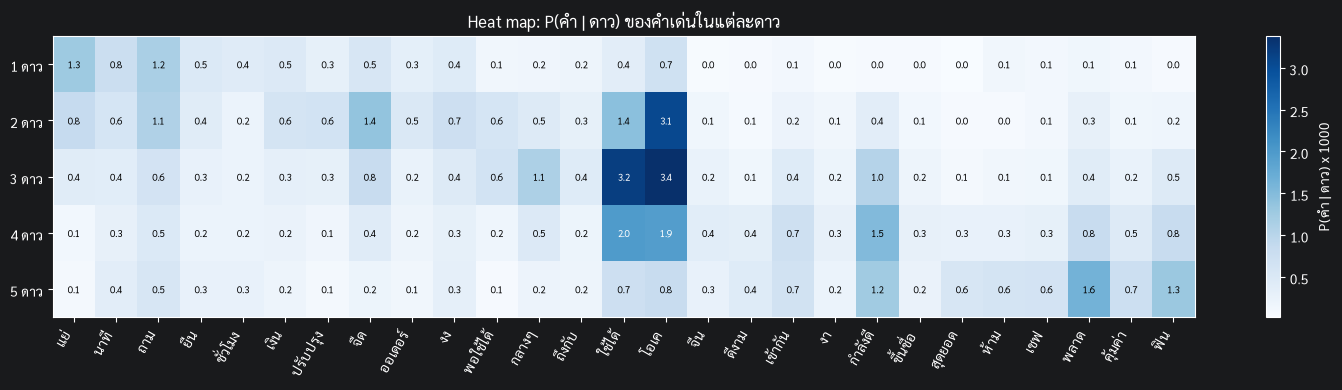

In [19]:
pick = []                                   # เลขคอลัมน์ของคำที่จะแสดง
for s in range(5):
  for i in np.argsort(-distinct_score(s))[:6]:
    if i not in pick:
      pick.append(i)

H = P[:, pick] * 1000
fig, ax = plt.subplots(figsize=(15, 4))
im = ax.imshow(H, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(pick)))
ax.set_xticklabels(words[pick], rotation=60, ha='right')
ax.set_yticks(range(5))
ax.set_yticklabels(['%d ดาว' % s for s in range(1, 6)])
for r in range(5):
  for c in range(len(pick)):
    ax.text(c, r, '%.1f' % H[r, c], ha='center', va='center', fontsize=7,
            color='white' if H[r, c] > H.max() * 0.55 else 'black')
fig.colorbar(im, label='P(คำ | ดาว) x 1000')
ax.set_title('Heat map: P(คำ | ดาว) ของคำเด่นในแต่ละดาว')
plt.tight_layout()
plt.show()

## 10. Word cloud 6 รูป
- **รวมทุกดาว**: ขนาดคำ = ความถี่ (จึงเป็นคำที่ใช้บ่อยทุกรีวิว)
- **1-5 ดาว**: ขนาดคำ = ความโดดเด่นเทียบกับดาวอื่น (จากข้อ 8) เพื่อดูว่าคำไหนมีอิทธิพลต่อการให้ดาวนั้น

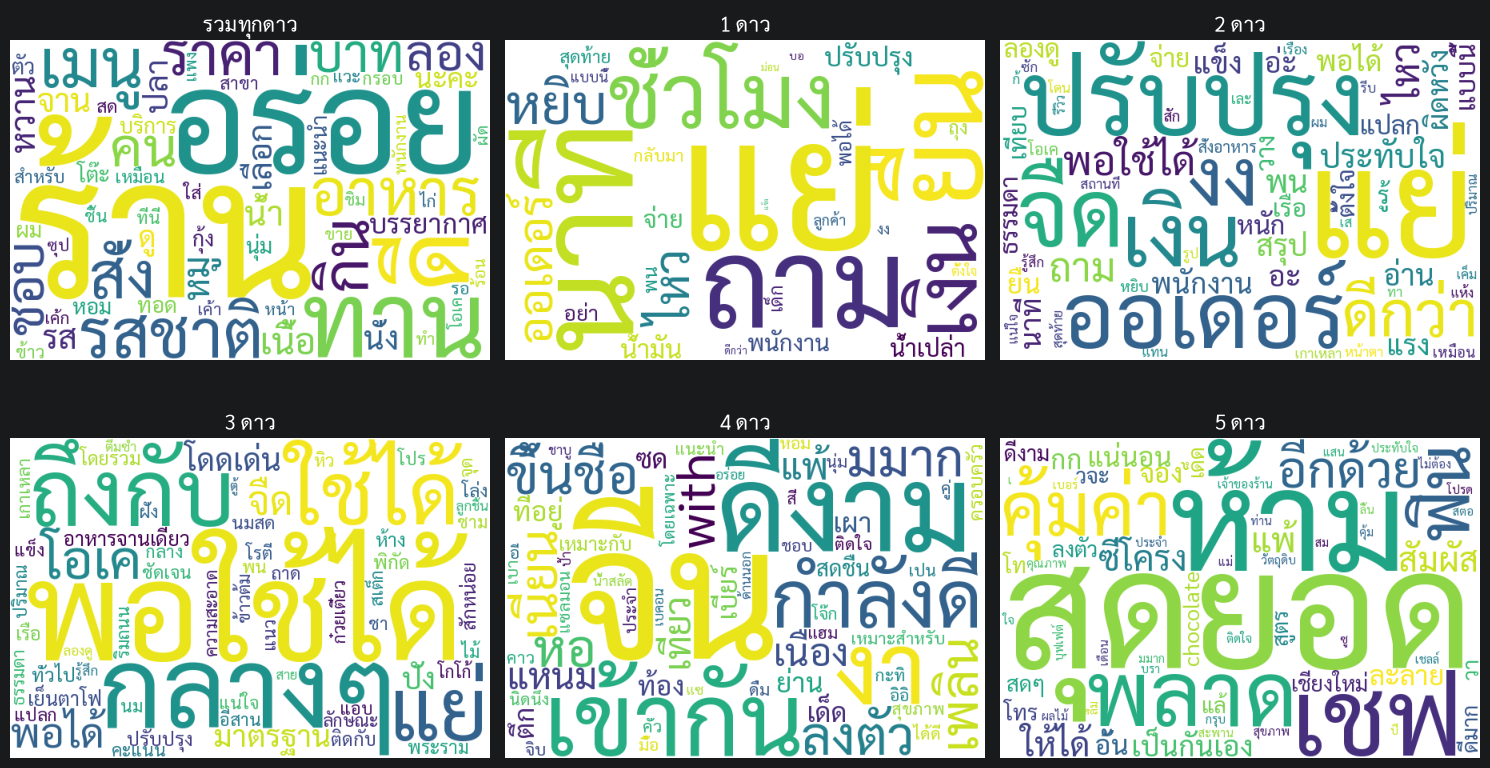

In [20]:
def make_cloud(freq):
  return WordCloud(font_path=FONT, width=600, height=400, background_color='white',
                   max_words=60, random_state=0).generate_from_frequencies(freq)

clouds = []
top = np.argsort(-total)[:100]
clouds.append(('รวมทุกดาว', {words[i]: float(total[i]) for i in top}))
for s in range(5):
  score = distinct_score(s)
  top = np.argsort(-score)[:60]
  clouds.append(('%d ดาว' % (s + 1), {words[i]: float(score[i]) for i in top if score[i] > 0}))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (title, freq) in zip(axes.flatten(), clouds):
  ax.imshow(make_cloud(freq))
  ax.set_title(title, fontsize=15)
  ax.axis('off')
plt.tight_layout()
plt.show()

## 11. สรุป

In [21]:
print('Accuracy =', round(acc * 100, 1), '% (เทียบเดา', majority, 'ดาวตลอด =', round(baseline * 100, 1), '%)')
print()
print('คำเด่นของแต่ละดาว (ใช้ตัดสินดาวมากที่สุด):')
for s in range(5):
  top = np.argsort(-distinct_score(s))[:8]
  print(' ', s + 1, 'ดาว :', ' '.join(words[top]))
print()
print('ทายผิดบ่อยที่สุด: ดาวใกล้กัน (เช่น 3 กับ 4) ดูได้จาก Confusion matrix ข้างบน')

Accuracy = 51.2 % (เทียบเดา 4 ดาวตลอด = 46.3 %)

คำเด่นของแต่ละดาว (ใช้ตัดสินดาวมากที่สุด):
  1 ดาว : แย่ นาที ถาม ยืน ชั่วโมง เงิน หยิบ ไหว
  2 ดาว : แย่ ปรับปรุง จืด ออเดอร์ เงิน งง ดีกว่า พอใช้ได้
  3 ดาว : พอใช้ได้ กลางๆ ถึงกับ ใช้ได้ แย่ โอเค พอได้ จืด
  4 ดาว : จีน ดีงาม เข้ากัน งา กำลังดี ขึ้นชื่อ ลงตัว เนียน
  5 ดาว : สุดยอด ห้าม เชฟ พลาด คุ้มค่า ฟิน อีกด้วย ซี่โครง

ทายผิดบ่อยที่สุด: ดาวใกล้กัน (เช่น 3 กับ 4) ดูได้จาก Confusion matrix ข้างบน
